# 第 9 章 模拟醉汉行走：随机游走模拟 —— 代码实现

对应笔记 `docs/mc/ch09.md`。五个实验：1d 随机游走的轨迹与分布、扩散极限（方差线性增长与热核）、2d 布朗运动、赌徒破产、几何布朗运动与期权定价（vs Black–Scholes）。

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch09")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2032)

## 9.1 一维随机游走：轨迹与分布

每步 $\pm1$ 等概率。$S_n=\sum X_i$：$E[S_n]=0$，$\mathrm{Var}(S_n)=n$（独立方差可加）。直方图 vs $N(0,\sqrt n)$。

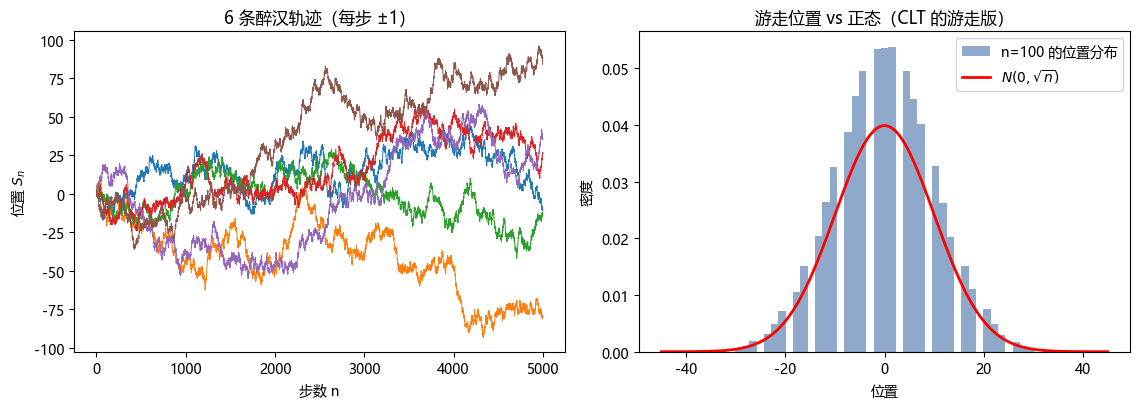

样本方差/步数 = 0.9983（理论 1.0：Var(S_n)=n）


In [8]:
npaths, nsteps = 6, 5000
steps = rng.choice([-1, 1], (npaths, nsteps))
S = steps.cumsum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for p in S:
    axes[0].plot(p, lw=0.7)
axes[0].set(title=f"{npaths} 条醉汉轨迹（每步 ±1）", xlabel="步数 n", ylabel="位置 $S_n$")

n_at = 100
end100 = rng.choice([-1, 1], (200_000, n_at)).sum(axis=1)
xx = np.linspace(-45, 45, 400)
axes[1].hist(end100, bins=61, range=(-45, 45), density=True, color="#8ea9c9", label=f"n={n_at} 的位置分布")
axes[1].plot(xx, stats.norm.pdf(xx, 0, np.sqrt(n_at)), "r-", lw=2, label=r"$N(0,\sqrt{n})$")
axes[1].set(title="游走位置 vs 正态（CLT 的游走版）", xlabel="位置", ylabel="密度"); axes[1].legend()
fig.tight_layout(); save(fig, "out-walk1d.png"); plt.show()
print(f"样本方差/步数 = {end100.var()/n_at:.4f}（理论 1.0：Var(S_n)=n）")

## 9.2 扩散极限：宽度 ∝ √n 与热核

多个 n 的位置直方图：标准差 √n 精确成立（对数坐标直线斜率 1/2）。

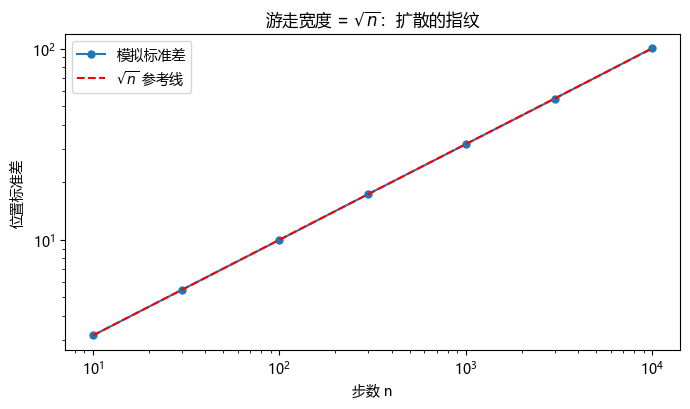

拟合斜率: 0.5001998885373047


In [9]:
ns = np.array([10, 30, 100, 300, 1000, 3000, 10000])
stds = []
for n in ns:
    ends = rng.choice([-1.0, 1.0], (100_000, n)).sum(axis=1)
    stds.append(ends.std())
stds = np.array(stds)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(ns, stds, "o-", ms=5, label="模拟标准差")
ax.loglog(ns, np.sqrt(ns), "r--", lw=1.5, label=r"$\sqrt{n}$ 参考线")
ax.set(title=r"游走宽度 = $\sqrt{n}$：扩散的指纹", xlabel="步数 n", ylabel="位置标准差")
ax.legend(); fig.tight_layout(); save(fig, "out-diffusion.png"); plt.show()
print("拟合斜率:", np.polyfit(np.log(ns), np.log(stds), 1)[0])

## 9.3 二维布朗运动

$W_{t+\Delta t}-W_t\sim N(0,\Delta t)$ 各分量独立。20 条平面轨迹，色彩随时间加深。

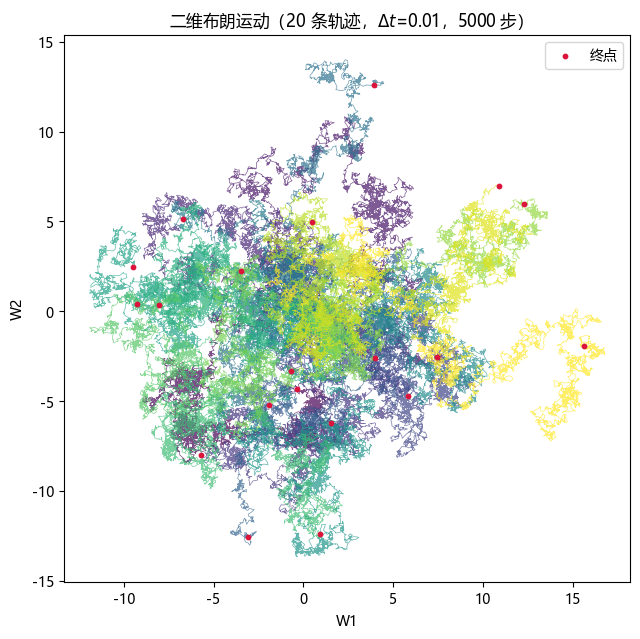

In [10]:
dt, nsteps2 = 0.01, 5000
dW = rng.normal(0, np.sqrt(dt), (20, nsteps2, 2))
W2 = dW.cumsum(axis=1)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
for i, w in enumerate(W2):
    ax.plot(w[:, 0], w[:, 1], lw=0.5, alpha=0.7, color=plt.cm.viridis(i / 19))
ax.scatter(W2[:, -1, 0], W2[:, -1, 0]*0 + W2[:, -1, 1], s=10, color="crimson", zorder=3, label="终点")
ax.set(title=f"二维布朗运动（20 条轨迹，$\\Delta t$={dt}，{nsteps2} 步）",
       xlabel="W1", ylabel="W2", aspect="equal")
ax.legend(); fig.tight_layout(); save(fig, "out-brownian2d.png"); plt.show()

## 9.4 赌徒破产

本金 $i$、目标 $N$，每局 ±1（胜率 p）。理论：公平 $P(\text{破产})=1-i/N$；不公平 $\frac{(q/p)^i-(q/p)^N}{(q/p)^N-1}$。模拟对撞。

p=0.5: 破产率 模拟 0.5011 vs 理论 0.5000；平均局数 625（理论 625）
p=0.45: 破产率 模拟 0.9938 vs 理论 0.9934；平均局数 247（理论 —）


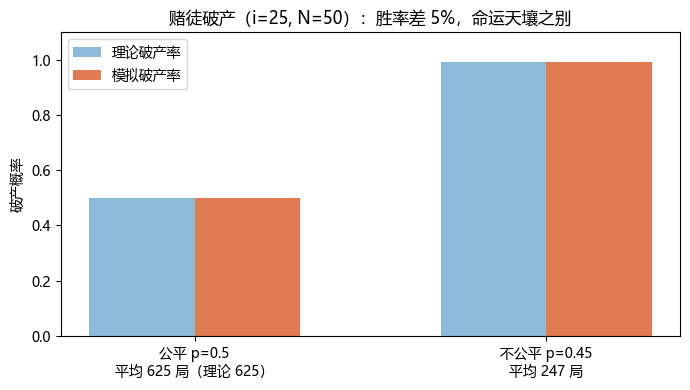

In [11]:
def gambler(i, N, p, rng, reps=40_000):
    out = np.zeros(reps, dtype=int)          # 结局：1=破产, 0=达标
    dur = np.empty(reps)
    for r in range(reps):
        x, t = i, 0
        while 0 < x < N:
            x += 1 if rng.random() < p else -1
            t += 1
        out[r] = 1 if x == 0 else 0
        dur[r] = t
    return out.mean(), dur.mean()

N, i = 50, 25
rows = []
for p in [0.5, 0.45]:
    ruin, dur = gambler(i, N, p, rng)
    if p == 0.5:
        ruin_t, dur_t = 1 - i/N, i*(N-i)
    else:
        r_ = (1-p)/p
        ruin_t = (r_**N - r_**i) / (r_**N - 1)
        dur_t = np.nan
    rows.append((p, ruin, ruin_t, dur, dur_t))
    print(f"p={p}: 破产率 模拟 {ruin:.4f} vs 理论 {ruin_t:.4f}；平均局数 {dur:.0f}（理论 {dur_t if p==0.5 else '—'}）")

fig, ax = plt.subplots(figsize=(7, 4))
pos = [0, 1]
ax.bar([x-0.15 for x in pos], [r[2] for r in rows], width=0.3, alpha=0.5, label="理论破产率")
ax.bar([x+0.15 for x in pos], [r[1] for r in rows], width=0.3, color="#e07b54", label="模拟破产率")
ax.set_xticks(pos, [f"公平 p=0.5\n平均 {rows[0][3]:.0f} 局（理论 625）", f"不公平 p=0.45\n平均 {rows[1][3]:.0f} 局"])
ax.set(ylabel="破产概率", title=f"赌徒破产（i={i}, N={N}）：胜率差 5%，命运天壤之别")
ax.set_ylim(0, 1.1)
ax.legend(); fig.tight_layout(); save(fig, "out-gambler.png"); plt.show()

## 9.5 几何布朗运动与期权定价

$S_T=S_0\exp((r-\sigma^2/2)T+\sigma\sqrt T\,Z)$，看涨期权 $C=e^{-rT}E[(S_T-K)^+]$。模拟 vs Black–Scholes。

MC 估计 C = 8.0321 ± 0.0296
Black–Scholes C = 8.0214（偏差 +0.0107，在 1 个误差棒内：True）
E[S_T] = 105.102（理论 S0·e^{rT} = 105.127）← 校正项 -σ²/2 的作用


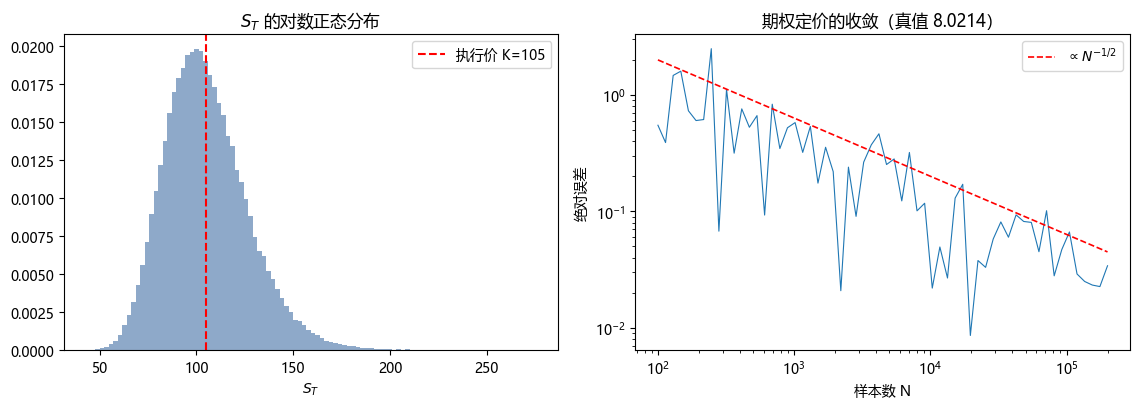

In [12]:
S0, K, r, sigma, T = 100.0, 105.0, 0.05, 0.20, 1.0
Nmc = 200_000
Z = rng.standard_normal(Nmc)
ST = S0 * np.exp((r - sigma**2/2)*T + sigma*np.sqrt(T)*Z)
payoff = np.maximum(ST - K, 0)
C_mc = np.exp(-r*T) * payoff.mean()
se = np.exp(-r*T) * payoff.std() / np.sqrt(Nmc)

d1 = (np.log(S0/K) + (r + sigma**2/2)*T) / (sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)
C_bs = S0*stats.norm.cdf(d1) - K*np.exp(-r*T)*stats.norm.cdf(d2)
print(f"MC 估计 C = {C_mc:.4f} ± {se:.4f}")
print(f"Black–Scholes C = {C_bs:.4f}（偏差 {C_mc-C_bs:+.4f}，在 1 个误差棒内：{abs(C_mc-C_bs)<se}）")
print(f"E[S_T] = {ST.mean():.3f}（理论 S0·e^{{rT}} = {S0*np.exp(r*T):.3f}）← 校正项 -σ²/2 的作用")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].hist(ST, bins=100, density=True, color="#8ea9c9")
axes[0].axvline(K, color="r", ls="--", lw=1.5, label=f"执行价 K={K:.0f}")
axes[0].set(title="$S_T$ 的对数正态分布", xlabel="$S_T$"); axes[0].legend()
Ns = np.geomspace(100, Nmc, 60)
est = [np.exp(-r*T)*np.maximum(S0*np.exp((r-sigma**2/2)*T + sigma*np.sqrt(T)*rng.standard_normal(int(n))) - K, 0).mean() for n in Ns]
axes[1].loglog(Ns, np.abs(np.array(est) - C_bs), lw=0.8)
axes[1].loglog(Ns, 20/np.sqrt(Ns), "r--", lw=1.2, label=r"$\propto N^{-1/2}$")
axes[1].set(title=f"期权定价的收敛（真值 {C_bs:.4f}）", xlabel="样本数 N", ylabel="绝对误差")
axes[1].legend()
fig.tight_layout(); save(fig, "out-option.png"); plt.show()